# 2 · Random-matrix denoising and Hierarchical Risk Parity
Sample correlation matrices are noisy: most of their eigenvalues are indistinguishable from those of random data. We
1. fit the **Marcenko-Pastur** distribution to separate signal from noise,
2. **denoise** and **detone** the matrix,
3. build **Hierarchical Risk Parity** portfolios (quasi-diagonalisation + recursive bisection).

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
prices = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_prices.py
bench = prices.pop("SPY")
rets = np.log(prices).diff().dropna()
RF = 0.025  # average T-bill rate over the sample (approx.)
from portopt import covariance, optimize

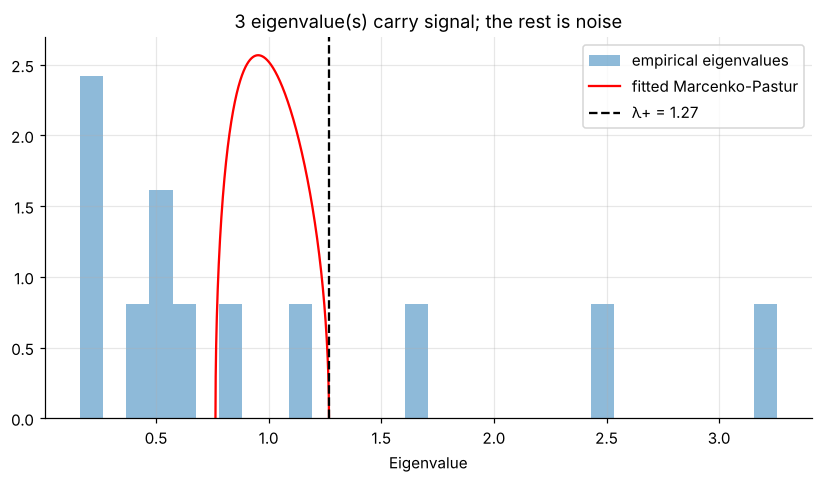

Top eigenvalues: [3.26 2.46 1.62 1.11]
Condition number: sample 35 -> denoised 20


In [2]:
window = rets.iloc[-756:]                           # last 3 years
cov_s = covariance.sample(window)
cov_d, n_facts, lam_max = covariance.denoise(cov_s, n_obs=len(window))
corr_s, _ = covariance.cov_to_corr(cov_s.values)
eig = np.sort(np.linalg.eigvalsh(corr_s))[::-1]
q = len(window) / len(cov_s)
mp = covariance.marcenko_pastur_pdf(lam_max / (1 + (1 / q) ** 0.5) ** 2, q)
plt.hist(eig, bins=30, density=True, alpha=0.5, label="empirical eigenvalues")
plt.plot(mp.index, mp.values, "r", label="fitted Marcenko-Pastur")
plt.axvline(lam_max, color="k", ls="--", label=f"λ+ = {lam_max:.2f}")
plt.title(f"{n_facts} eigenvalue(s) carry signal; the rest is noise"); plt.xlabel("Eigenvalue"); plt.legend()
plt.savefig(IMG / "marcenko_pastur.png", bbox_inches="tight"); plt.show()
print("Top eigenvalues:", eig[:4].round(2))
print(f"Condition number: sample {np.linalg.cond(cov_s):,.0f} -> denoised {np.linalg.cond(cov_d):,.0f}")

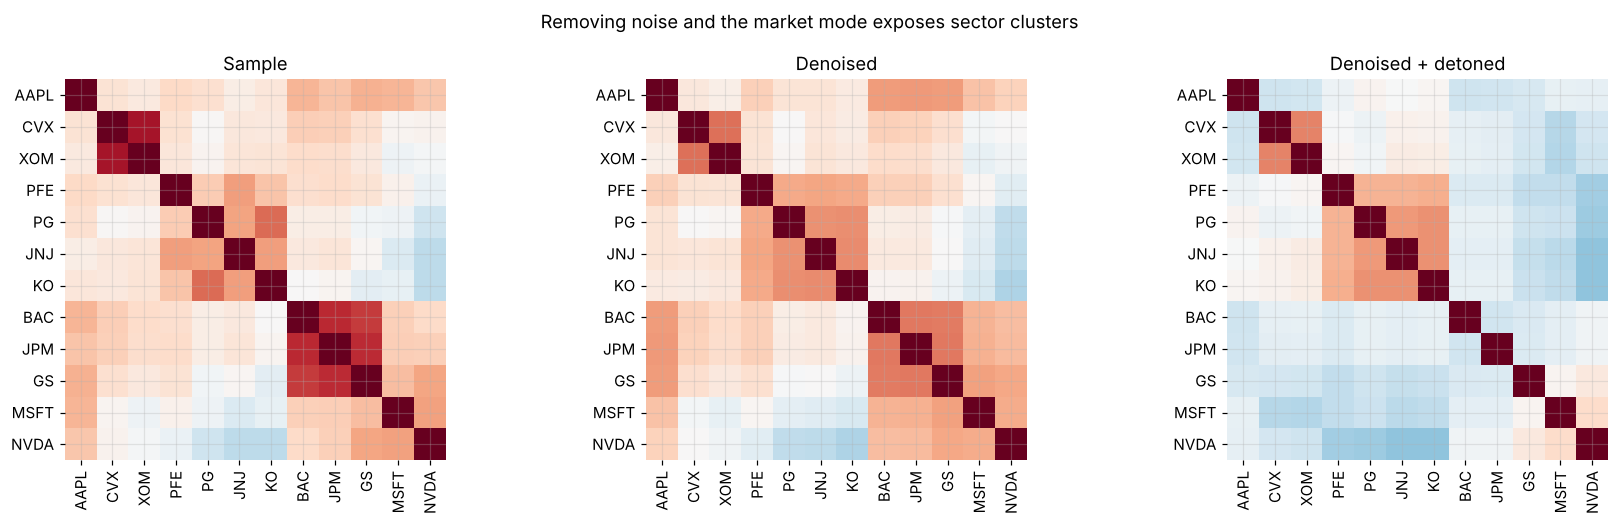

In [3]:
corr_dt = covariance.detone(cov_d)
order = optimize.quasi_diag_order(corr_dt)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, (title, m) in zip(ax, [("Sample", window.corr()), ("Denoised", pd.DataFrame(covariance.cov_to_corr(cov_d.values)[0], cov_d.index, cov_d.columns)),
                               ("Denoised + detoned", corr_dt)]):
    sns.heatmap(m.loc[order, order], cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=a, cbar=False, square=True)
    a.set_title(title)
fig.suptitle("Removing noise and the market mode exposes sector clusters"); fig.tight_layout()
plt.savefig(IMG / "denoise_detone.png", bbox_inches="tight"); plt.show()

## HRP vs other risk-based allocations

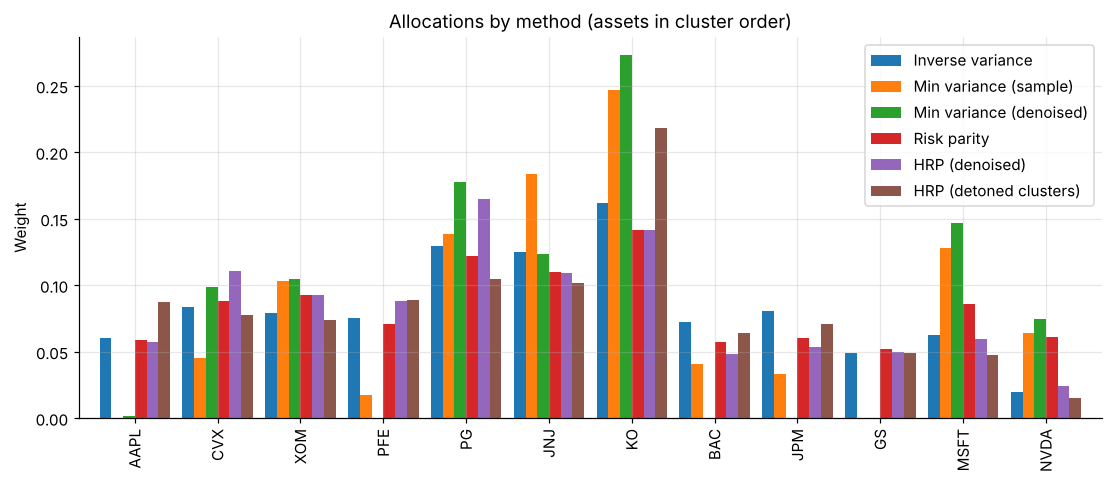

,Inverse variance,Min variance (sample),Min variance (denoised),Risk parity,HRP (denoised),HRP (detoned clusters)
AAPL,0.061,0.000,0.001,0.059,0.057,0.088
BAC,0.072,0.041,0.000,0.057,0.048,0.064
CVX,0.083,0.045,0.098,0.088,0.111,0.078
GS,0.049,0.000,0.000,0.052,0.050,0.049
JNJ,0.125,0.183,0.123,0.110,0.109,0.102
JPM,0.081,0.033,0.000,0.060,0.054,0.071
KO,0.162,0.247,0.273,0.142,0.141,0.218
MSFT,0.063,0.128,0.147,0.086,0.059,0.048
NVDA,0.020,0.064,0.075,0.061,0.024,0.015
PFE,0.076,0.017,0.000,0.071,0.088,0.089


In [4]:
alloc = pd.DataFrame({
    "Inverse variance": (1 / np.diag(cov_d)) / (1 / np.diag(cov_d)).sum(),
    "Min variance (sample)": optimize.min_variance(cov_s),
    "Min variance (denoised)": optimize.min_variance(cov_d),
    "Risk parity": optimize.risk_parity(cov_d),
    "HRP (denoised)": optimize.hrp(cov_d),
    "HRP (detoned clusters)": optimize.hrp(cov_d, corr=corr_dt)}, index=cov_s.index)
ax = alloc.loc[order].plot.bar(figsize=(12, 4.5), width=0.85)
ax.set_title("Allocations by method (assets in cluster order)"); ax.set_ylabel("Weight")
plt.savefig(IMG / "hrp_allocations.png", bbox_inches="tight"); plt.show()
alloc.round(3)

In [5]:
conc = pd.DataFrame({"max weight": alloc.max(), "effective # assets (1/HHI)": 1 / (alloc**2).sum(),
                     "ex-ante vol": [np.sqrt(w @ cov_d @ w) for _, w in alloc.items()]})
conc.round(3)

,max weight,effective # assets (1/HHI),ex-ante vol
Inverse variance,0.162,10.022,0.110
Min variance (sample),0.247,6.668,0.100
Min variance (denoised),0.273,5.914,0.098
Risk parity,0.142,10.806,0.109
HRP (denoised),0.165,9.722,0.109
HRP (detoned clusters),0.218,9.083,0.112


**Takeaway:** min-variance on the raw sample matrix concentrates in a handful of names. HRP keeps the low-risk tilt but spreads weight across clusters, so it holds noticeably more *effective* assets. Notebook 4 tests whether that survives out-of-sample.